# Лабораторная работа №1. Проведение исследований с алгоритмом KNN

**Студент:** Чибугаев Илья Алексеевич  
**Вариант:** 22  
**Случайное зерно:** 22

## Исходные данные

- **Классификация:** [Ionosphere, UCI](https://archive.ics.uci.edu/dataset/52/ionosphere) — 351 объект, 34 числовых признака; `bad=1` обозначает сигнал без структуры в ионосфере.
- **Регрессия:** [Concrete Compressive Strength, UCI](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength) — 1030 составов бетона, 8 признаков, целевая переменная — прочность в МПа.

Датасеты выбраны для разных практических задач: контроль качества радиосигнала и предварительная оценка рецептуры бетона. Оба набора небольшие, содержат только числовые признаки и позволяют сопоставить алгоритмы без изменения задачи между лабораторными.

KNN сохраняет обучающие объекты и относит новый объект к классу большинства либо усредняет ответы ближайших соседей. Поэтому масштаб признаков, метрика расстояния и число соседей непосредственно определяют качество.

## Протокол и метрики

Для обеих задач используется фиксированное разбиение **80% / 20%** с `random_state=22`; в классификации разбиение стратифицировано. Подбор параметров выполняется только внутри обучающей выборки. Все четыре конфигурации (sklearn / собственная, базовая / улучшенная) оцениваются на одном и том же тестовом наборе.

- **Классификация:** основная метрика — **ROC-AUC**, поскольку она оценивает ранжирование и не зависит от одного порога; **F1** контролирует качество по классу `bad`, а **accuracy** показывает общую долю верных ответов.
- **Регрессия:** основная метрика — **RMSE (МПа)**, штрафующая крупные ошибки; **MAE (МПа)** даёт типичную абсолютную ошибку, **R²** — долю объяснённой дисперсии.


## 1. Подготовка

Код импортирует только общие функции и фиксирует настройки отображения. Каждая следующая ячейка имеет отдельный комментарий.

In [1]:
# Настраиваем воспроизводимое окружение и импортируем общий код эксперимента.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.experiments import TaskExperiment, LAB_NAMES

pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)
plt.style.use("seaborn-v0_8-whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)
print(f"Корень проекта: {ROOT}")

Matplotlib is building the font cache; this may take a moment.


Корень проекта: /Users/finleyl/Documents/kimi/tasks/2026-11-10/20-02-04-6933ea61/ml-labs-1-5


### Загрузка и проверка разбиений

Проверяем размеры, отсутствие пропусков, баланс классов и диапазон целевой переменной. Разбиения одинаковы во всех пяти работах.

In [2]:
# Создаём эксперименты для двух задач и выводим контрольные характеристики данных.
experiments = {task: TaskExperiment(1, task) for task in ("classification", "regression")}
for task, experiment in experiments.items():
    data = experiment.data
    print(f"{task}: {data.name}")
    print(data.practical_task)
    print(f"train={data.X_train.shape}, test={data.X_test.shape}, пропуски={int(data.X.isna().sum().sum())}")
    if task == "classification":
        print(f"Доля bad: train={data.y_train.mean():.3f}, test={data.y_test.mean():.3f}")
    else:
        print(data.y.describe().to_string())
    print()

classification: Ionosphere (UCI)
По сигналам фазированной антенной решётки отличать радиосигналы со структурой в ионосфере от проходящих сигналов.
train=(280, 34), test=(71, 34), пропуски=0
Доля bad: train=0.361, test=0.352

regression: Concrete Compressive Strength (UCI)
По составу смеси и возрасту бетона прогнозировать прочность на сжатие в МПа для предварительной оценки рецептуры.
train=(824, 8), test=(206, 8), пропуски=0
count    1030.0000
mean       35.8178
std        16.7057
min         2.3318
25%        23.7071
50%        34.4428
75%        46.1363
max        82.5992



## 2. Исследование данных

Визуализация проверяет исходные предположения: дисбаланс классов, константные сигналы и нелинейную связь состава бетона с прочностью. Графики не используются для подбора на тестовой выборке.

Константные признаки Ionosphere: ['signal_02']


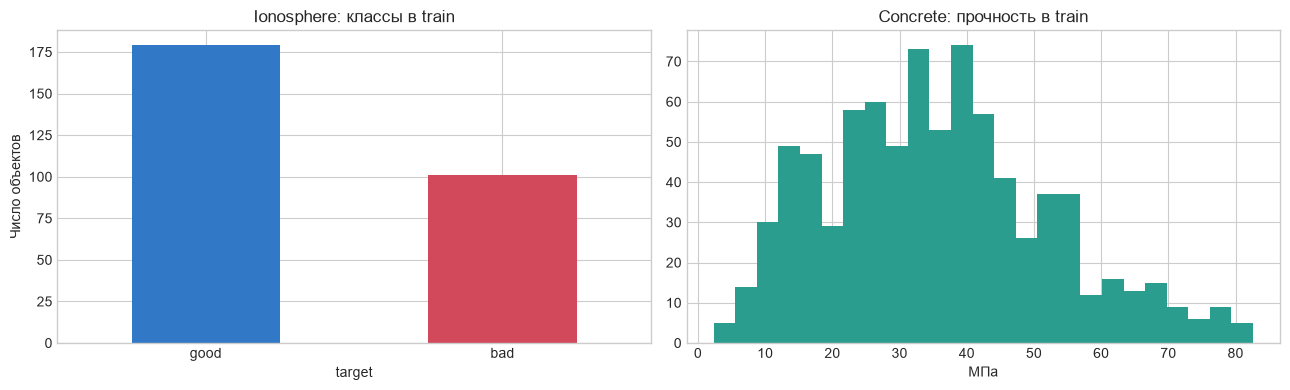

,Корреляция Пирсона с прочностью
water,-0.2804
fine_aggregate,-0.1645
coarse_aggregate,-0.1633
fly_ash,-0.1118
blast_furnace_slag,0.1311
age_days,0.3354
superplasticizer,0.3520
cement,0.4944


In [3]:
# Строим распределение классов, гистограмму прочности и корреляции признаков бетона.
classification = experiments["classification"].data
regression = experiments["regression"].data
constant_features = classification.X_train.columns[classification.X_train.nunique() <= 1].tolist()
print("Константные признаки Ionosphere:", constant_features)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
classification.y_train.map({0: "good", 1: "bad"}).value_counts().plot(kind="bar", ax=axes[0], color=["#3178c6", "#d1495b"])
axes[0].set_title("Ionosphere: классы в train")
axes[0].set_ylabel("Число объектов")
axes[0].tick_params(axis="x", rotation=0)
regression.y_train.hist(bins=25, ax=axes[1], color="#2a9d8f")
axes[1].set_title("Concrete: прочность в train")
axes[1].set_xlabel("МПа")
plt.tight_layout()
plt.show()

corr = regression.X_train.assign(strength_mpa=regression.y_train).corr()["strength_mpa"].drop("strength_mpa").sort_values()
display(corr.to_frame("Корреляция Пирсона с прочностью"))

## 3. Базовый бейзлайн sklearn

Бейзлайн использует параметры алгоритма по умолчанию и только медианное заполнение пропусков. Это точка отсчёта, а не ожидаемый победитель.

In [4]:
# Обучаем базовые sklearn-модели и оцениваем их на отложенной выборке.
for experiment in experiments.values():
    experiment.fit_sklearn_baseline()
baseline_results = pd.concat([experiment.results for experiment in experiments.values()], ignore_index=True)
display(baseline_results.drop(columns=["params"]))

classification | sklearn | baseline: accuracy=0.8169, f1=0.6486, roc_auc=0.8683; 0.00 s
regression | sklearn | baseline: rmse=8.8069, mae=7.0053, r2=0.7403; 0.00 s


,lab,algorithm,task,implementation,stage,accuracy,f1,roc_auc,rmse,mae,r2,fit_seconds
0,1,KNN,classification,sklearn,baseline,0.8169,0.6486,0.8683,NaN,NaN,NaN,0.0022
1,1,KNN,regression,sklearn,baseline,NaN,NaN,NaN,8.8069,7.0053,0.7403,0.0016


## 4. Улучшение бейзлайна

### Проверяемые гипотезы

1. Стандартизация признаков устранит доминирование переменных с большим масштабом в расстоянии Минковского.
2. Удаление константных признаков не потеряет информацию, но сократит вычисления.
3. Число соседей, взвешивание по обратному расстоянию и норма p будут подобраны по 5-блочной кросс-валидации.

Метрика подбора — ROC-AUC для классификации и RMSE для регрессии. Лучшие параметры затем один раз оцениваются на тесте.

In [5]:
# Запускаем GridSearchCV и показываем пять лучших конфигураций для каждой задачи.
for experiment in experiments.values():
    experiment.fit_sklearn_improved()
    print(f"{experiment.task}: лучшие параметры = {experiment.search.best_params_}")
    display(experiment.cv_table().head())

classification | sklearn | improved: accuracy=0.8592, f1=0.7500, roc_auc=0.9361; 1.55 s
classification: лучшие параметры = {'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'distance'}


,params,cv_roc_auc,std_roc_auc,mean_fit_time
0,"{'model__n_neighbors': 7, 'model__p': 1, 'mode...",0.9523,0.0244,0.0026
1,"{'model__n_neighbors': 11, 'model__p': 1, 'mod...",0.9488,0.0232,0.0026
2,"{'model__n_neighbors': 5, 'model__p': 1, 'mode...",0.9483,0.0228,0.0043
3,"{'model__n_neighbors': 7, 'model__p': 1, 'mode...",0.9480,0.0233,0.0027
4,"{'model__n_neighbors': 5, 'model__p': 1, 'mode...",0.9447,0.0203,0.0036


regression | sklearn | improved: rmse=7.7874, mae=5.7290, r2=0.7969; 0.06 s
regression: лучшие параметры = {'model__n_neighbors': 7, 'model__p': 2, 'model__weights': 'distance'}


,params,cv_rmse,std_rmse,mean_fit_time
0,"{'model__n_neighbors': 7, 'model__p': 2, 'mode...",8.5331,0.2396,0.0027
1,"{'model__n_neighbors': 5, 'model__p': 2, 'mode...",8.6156,0.2364,0.0023
2,"{'model__n_neighbors': 11, 'model__p': 2, 'mod...",8.6738,0.3844,0.0021
3,"{'model__n_neighbors': 7, 'model__p': 1, 'mode...",8.8837,0.4465,0.0023
4,"{'model__n_neighbors': 11, 'model__p': 1, 'mod...",8.9090,0.3814,0.0022


### Сравнение базового и улучшенного sklearn-бейзлайна

Положительная разница ROC-AUC/F1/accuracy/R² означает улучшение; для RMSE/MAE улучшение соответствует отрицательной разнице.

In [6]:
# Формируем таблицу изменений метрик между улучшенной и базовой sklearn-моделями.
metric_names = {"classification": ["roc_auc", "f1", "accuracy"], "regression": ["rmse", "mae", "r2"]}
for task, experiment in experiments.items():
    rows = experiment.results.set_index("stage")
    metrics = metric_names[task]
    comparison = rows.loc[["baseline", "improved"], metrics].T
    comparison["change"] = comparison["improved"] - comparison["baseline"]
    print(task)
    display(comparison)

classification


stage,baseline,improved,change
roc_auc,0.8683,0.9361,0.0678
f1,0.6486,0.7500,0.1014
accuracy,0.8169,0.8592,0.0423


regression


stage,baseline,improved,change
rmse,8.8069,7.7874,-1.0194
mae,7.0053,5.7290,-1.2763
r2,0.7403,0.7969,0.0566


## 5. Собственная реализация

Расстояния считаются матричными операциями NumPy; для экономии памяти прогноз строится блоками. Взвешивание обрабатывает нулевые расстояния без деления на ноль.

Исходный код находится в `src/models/`. Сначала используются базовые параметры, затем техники и параметры улучшенного бейзлайна.

In [7]:
# Обучаем собственные базовые модели на тех же преобразованных данных, что и sklearn-бейзлайн.
for experiment in experiments.values():
    experiment.fit_custom_baseline()
custom_baseline_results = pd.concat([
    experiment.results[experiment.results["implementation"] == "from_scratch"]
    for experiment in experiments.values()
], ignore_index=True)
display(custom_baseline_results.drop(columns=["params"]))

classification | from_scratch | baseline: accuracy=0.8169, f1=0.6486, roc_auc=0.8683; 0.00 s
regression | from_scratch | baseline: rmse=8.8069, mae=7.0053, r2=0.7403; 0.00 s


,lab,algorithm,task,implementation,stage,accuracy,f1,roc_auc,rmse,mae,r2,fit_seconds
0,1,KNN,classification,from_scratch,baseline,0.8169,0.6486,0.8683,NaN,NaN,NaN,4.5125e-05
1,1,KNN,regression,from_scratch,baseline,NaN,NaN,NaN,8.8069,7.0053,0.7403,1.2709e-05


### Собственная модель с улучшенным бейзлайном

Преобразования обучены только на train. Для собственной модели переносятся выбранные на CV параметры; исключение по числу деревьев случайного леса явно указано в гипотезах.

In [8]:
# Добавляем улучшенный препроцессинг и выбранные параметры в собственные реализации.
for experiment in experiments.values():
    experiment.fit_custom_improved()
all_lab_results = pd.concat([experiment.results for experiment in experiments.values()], ignore_index=True)
display(all_lab_results.drop(columns=["params"]))

classification | from_scratch | improved: accuracy=0.8592, f1=0.7500, roc_auc=0.9361; 0.00 s
regression | from_scratch | improved: rmse=7.7874, mae=5.7290, r2=0.7969; 0.00 s


,lab,algorithm,task,implementation,stage,accuracy,f1,roc_auc,rmse,mae,r2,fit_seconds
0,1,KNN,classification,sklearn,baseline,0.8169,0.6486,0.8683,NaN,NaN,NaN,2.1923e-03
1,1,KNN,classification,sklearn,improved,0.8592,0.7500,0.9361,NaN,NaN,NaN,1.5550e+00
2,1,KNN,classification,from_scratch,baseline,0.8169,0.6486,0.8683,NaN,NaN,NaN,4.5125e-05
3,1,KNN,classification,from_scratch,improved,0.8592,0.7500,0.9361,NaN,NaN,NaN,3.2500e-05
4,1,KNN,regression,sklearn,baseline,NaN,NaN,NaN,8.8069,7.0053,0.7403,1.6189e-03
5,1,KNN,regression,sklearn,improved,NaN,NaN,NaN,7.7874,5.7290,0.7969,5.7185e-02
6,1,KNN,regression,from_scratch,baseline,NaN,NaN,NaN,8.8069,7.0053,0.7403,1.2709e-05
7,1,KNN,regression,from_scratch,improved,NaN,NaN,NaN,7.7874,5.7290,0.7969,9.5000e-06


## 6. Сохранение результатов и выводы

Вывод формируется по фактическим значениям, а не по предположению, что улучшение обязано помочь. На маленькой тестовой выборке небольшие различия не следует трактовать как статистически доказанное превосходство.

In [9]:
# Сохраняем четыре результата на задачу и печатаем аргументированное заключение по каждой задаче.
output_path = ROOT / "results" / "lab01_results.csv"
output_path.parent.mkdir(exist_ok=True)
all_lab_results.to_csv(output_path, index=False)

for task, experiment in experiments.items():
    frame = experiment.results.set_index(["implementation", "stage"])
    metrics = metric_names[task]
    sklearn_base = frame.loc[("sklearn", "baseline"), metrics]
    sklearn_best = frame.loc[("sklearn", "improved"), metrics]
    custom_base = frame.loc[("from_scratch", "baseline"), metrics]
    custom_best = frame.loc[("from_scratch", "improved"), metrics]
    primary = "roc_auc" if task == "classification" else "rmse"
    higher_is_better = primary != "rmse"
    sklearn_change = sklearn_best[primary] - sklearn_base[primary]
    custom_change = custom_best[primary] - custom_base[primary]
    sklearn_verdict = "улучшился" if (sklearn_change > 0) == higher_is_better else "не улучшился"
    custom_verdict = "улучшился" if (custom_change > 0) == higher_is_better else "не улучшился"
    print(f"{task}: sklearn {primary} {sklearn_base[primary]:.4f} → {sklearn_best[primary]:.4f} ({sklearn_verdict}); "
          f"своя реализация {custom_base[primary]:.4f} → {custom_best[primary]:.4f} ({custom_verdict}).")
    print(f"Лучшие параметры sklearn: {experiment.search.best_params_}")
print(f"Результаты сохранены: {output_path.relative_to(ROOT)}")

classification: sklearn roc_auc 0.8683 → 0.9361 (улучшился); своя реализация 0.8683 → 0.9361 (улучшился).
Лучшие параметры sklearn: {'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'distance'}
regression: sklearn rmse 8.8069 → 7.7874 (улучшился); своя реализация 8.8069 → 7.7874 (улучшился).
Лучшие параметры sklearn: {'model__n_neighbors': 7, 'model__p': 2, 'model__weights': 'distance'}
Результаты сохранены: results/lab01_results.csv
